*Notebook 07 of 12 in `notebooks/scripts_text/`. Parameters: `analysis/scripts_text/config.yaml`; decisions and run notes: `analysis/scripts_text/LOG.md`. The static page `site/scripts/index.html` is built from the same outputs.*

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().resolve().parents[1]   # notebooks/scripts_text -> repo root
sys.path.insert(0, str(REPO))

import warnings

import pandas as pd
import plotly.io as pio
from IPython.display import Markdown, display

from analysis.static_figures import use_static_figures

from analysis.scripts_text import s07_stability as step

use_static_figures()   # figures become static PNGs (they show on GitHub); interactive ones are on the static page
warnings.filterwarnings("ignore", category=RuntimeWarning)   # known 0/0 on very short arcs, handled downstream
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

## Step 7 · Stability: one run is one sample, not the answer

**What we do.** We draw 100 random subsamples of the larger group, each the size of the smaller group (seeds
logged in `run_log.json`), recompute the Scattertext and record, for each term in the full-sample top 50, the
share of runs in which it stays in the top 50. For the matched design we vary the caliper (0.25, 0.5 and 1
standard deviations of log budget) and the order in which scripts are matched (20 orders each).

**Why.** A top-50 list from one sample can depend on which particular profitable scripts happened to be
included. If a term survives in most subsamples it isn't carried by a few scripts. Same logic as running
Louvain with many seeds (week 4): one run is one draw.

**What it measures.** How sensitive the word lists are to the sample, as a survival share per term and a
Jaccard overlap per run.

**What it misses.** Stable isn't the same as meaningful: a formatting artefact used by many scripts would be
very stable. Step 8 reads the text.

In [2]:
res = step.run()   # recomputes this step and saves its outputs

**Figure.** For each term in the full-sample top 50 (x: its rank), the share of 100 subsamples in which it stays in the top 50 (y). A flat line near 100% would mean the list doesn't depend on the sample; a fast drop means only the first few terms are robust.

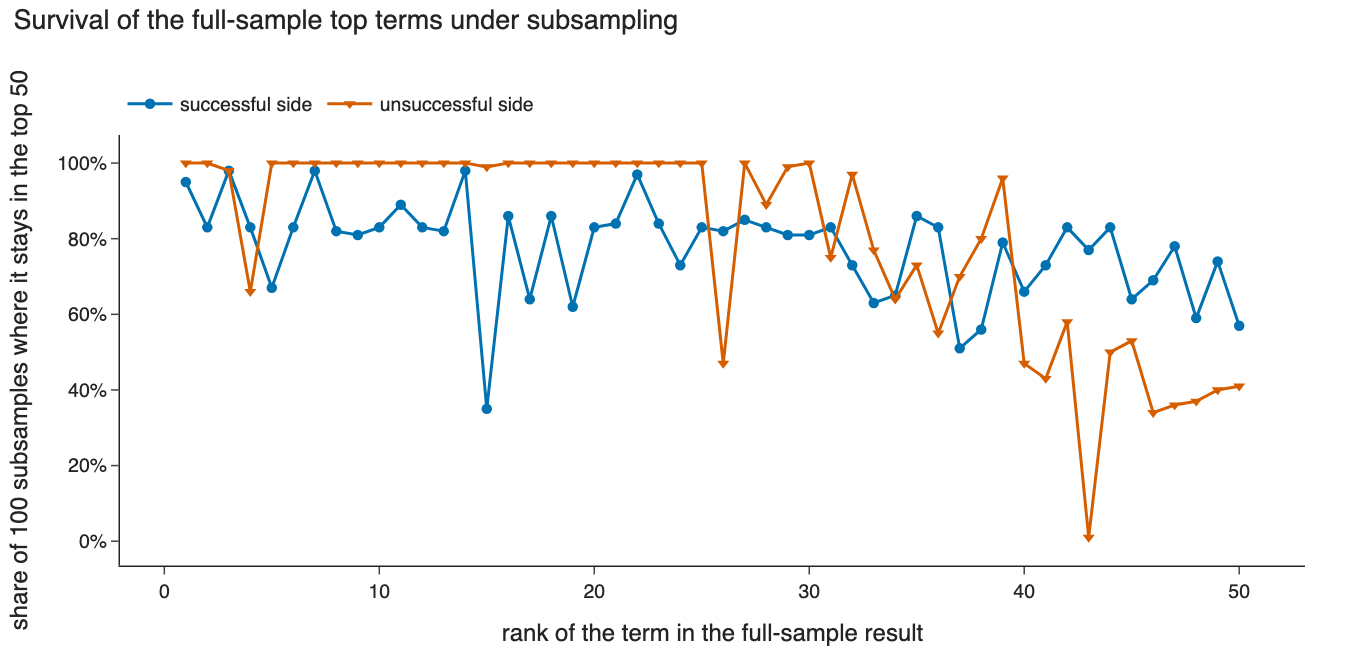

In [3]:
step.figures(res)["survival"].show()

**Table.** The 20 highest-ranked terms on each side and how often they survive.

In [4]:
display(step.tables(res)["survival_top20"])

,rank,successful term,share of runs,unsuccessful term,share of runs
0,1,je,0.95,jerry,1.00
1,2,pas,0.83,eddie,1.00
2,3,rocky,0.98,piper,0.98
3,4,c'est,0.83,padre,0.66
4,5,balboa,0.67,jake,1.00
5,6,il,0.83,gem,1.00
6,7,parker,0.98,sparky,1.00
7,8,yah,0.82,jimmy,1.00
8,9,chancellor,0.81,bloom,1.00
9,10,vous,0.83,films,1.00


**Figure.** Matched design: overlap of the top-50 lists with the main matched result, across calipers and 20 matching orders each.

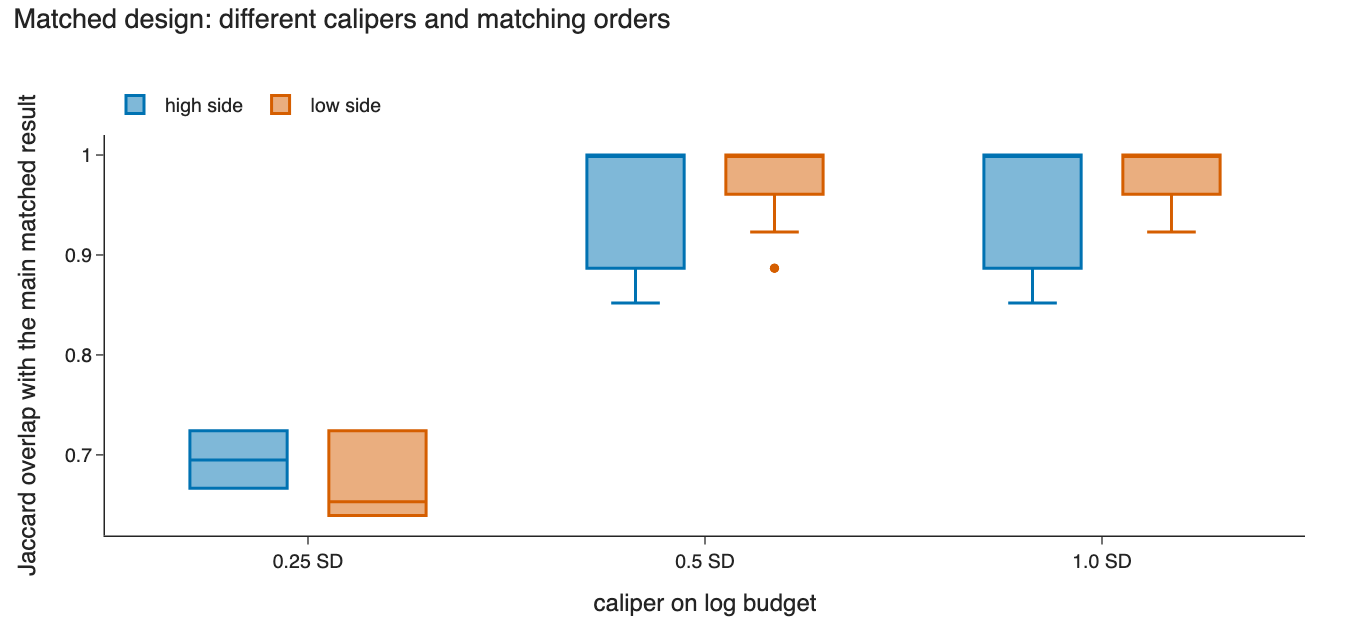

In [5]:
step.figures(res)["matched"].show()

**Table.** Median pairs and overlaps per caliper.

In [6]:
display(step.tables(res)["matched"])

,caliper_sd,pairs,jaccard_high,jaccard_low
0,0.25,61.0,0.69,0.65
1,0.50,67.0,1.00,1.00
2,1.00,67.0,1.00,1.00


**Plain-language reading** (generated from the saved numbers):

In [7]:
display(Markdown(step.reading(res)))

Subsampling the successful group down to 236 scripts, 100 times, the top-50 lists overlap the full-sample lists with a median Jaccard of 0.69 on the successful side and 0.67 on the unsuccessful side. 5 successful-side and 29 unsuccessful-side terms stay in the top 50 in at least 90% of runs; the rest come and go with the sample. In the matched design, changing the caliper and the matching order gives a median overlap of 0.89 (successful side) and 0.96 (unsuccessful side) with the main matched result. The full-sample result stays the main one; this is a robustness check.